# Q1F | Final Predictions

> *Make predictions of the labels on the test data, using the trained model with chosen (best) hyperparameters. Summarize performance using the RMSE.*

The trained models are the two that parts D and E selected, fit on the training data and saved: a linear regression and a polynomial regression.

---

#### IMPORTANT

This is the only notebook that scores a model on the `test` dataset. Both models were selected, fit and saved before it, on the training rows only, and nothing is refit or tuned here. The final model, the tables, the charts and the test for whether the cross validated estimate held were fixed in Method before any test score was computed, so no choice below is influenced by the test data (`data snooping`).

# Answer Summary

**Setup:** the two pipelines Q1D and Q1E saved are loaded as they are and predict the 334 test rows from the 8 stored attributes. Nothing is refit or tuned. The metric is rmse, in `Life Ladder` units. The final model is the polynomial regression, chosen from cross validation before any test row was predicted.

**Cross validated estimate, training rmse and test rmse**

| Model | cv rmse (lowest to highest fold) | train rmse | test rmse (95% interval) |
|---|---|---|---|
| Linear: Ridge SGD, `alpha=0.001`, `eta0=0.01` | 0.5164 (0.4730 to 0.5588) | 0.5128 | 0.5239 (0.4791 to 0.5700) |
| Polynomial (final): degree 2, Ridge SGD, `alpha=0.001`, `eta0=0.001` | 0.4889 (0.4421 to 0.5297) | 0.4789 | 0.5021 (0.4553 to 0.5498) |

The interval comes from a bootstrap over the test rows. It leaves out the noise from the training rows, so the true noise is at least this large.

- **Predictions:** each model predicts all 334 test rows. The final model's predictions run from 3.528 to 7.566, a narrower range than the actual values (2.694 to 7.858).
- **RMSE:** the final model's test rmse is 0.5021, with an mae of 0.3812 and an r2 of 0.8156. The linear model's is 0.5239. The polynomial model is lower by 0.0218, and the 95% interval of that difference (-0.0430 to -0.0021) does not include 0, though its upper end is close to it.
- **The cross validated estimates held.** Each test rmse is above its estimate and above its training rmse, but inside the range of its fold scores.
- **Where the predictions miss:** on the rows with a low actual value. The 37 test rows below 4 have an rmse of 0.7960 for the final model, which predicts them 0.6855 too high on average. It is most accurate on the rows it predicts at 7 and above (0.2370).

---

# Imports

In [1]:
import joblib
import numpy as np
import pandas as pd
from IPython.display import display
from sklearn.base import clone

from Q1.consts import *

from utils import (
	read_csv_to_df,
	PLOTTING,
	SCORING,
	PIPELINES,
)

# Fetch Data

In [2]:
train_df = read_csv_to_df(path=TRAIN_PATH)
test_df = read_csv_to_df(path=TEST_PATH)

ATTRIBUTES = [column["col"] for key, column in COLUMNS.items() if key != "LL"]

X = train_df[ATTRIBUTES]
y = train_df[TARGET]

# rows with no missing attribute: the rows both models were fit on in Q1D and Q1E
complete = X.notna().all(axis=1)
X_complete = X[complete]
y_complete = y[complete]

X_test = test_df[ATTRIBUTES]
y_test = test_df[TARGET]

# neither saved pipeline has an imputer, so a test row with a missing value could not be predicted
assert X_test.notna().all().all(), "a test row has a missing value"

print(f"attributes: {len(ATTRIBUTES)}")
pd.DataFrame({
	"rows": [len(X), len(X_test)],
	"rows with a missing value": [int((~complete).sum()), int(X_test.isna().any(axis=1).sum())],
	"rows used": [len(X_complete), len(X_test)],
}, index=["train", "test"])

attributes: 8


,rows,rows with a missing value,rows used
train,1559,185,1374
test,334,0,334


# Method

Q1D and Q1E each selected one model with cross validation, fit it once on the 1,374 complete training rows and saved it as one `Pipeline`. Both are loaded here as they were saved. Each takes the 8 attributes as they are stored and builds its own feature columns, so this notebook does no preprocessing.

- **Nothing is refit or tuned.** The test rows are used once, to score the two saved fits. No hyperparameter, feature or model choice changes after a test score is seen.
- **Check on the files:** the hyperparameters are read back from the loaded pipelines, and each fit's epochs and training rmse are compared with the values Q1D and Q1E printed (`REPORTED`).
- **Cross validated estimate:** a clone of each pipeline (the same steps and hyperparameters, none of the fitted values) is scored on the 20 folds of Q1D and Q1E. The clones are fit on training folds only, and the saved fits are not changed. A fold's rmse is a score on rows its model did not train on, so the mean over the folds is the estimate of the test rmse.
- **The final model is the polynomial regression,** Q1E's. Its cross validated rmse is lower than the linear model's by more than 1 SE of the per-fold differences, the **candidate** verdict of Q1D and Q1E, and Cross Validated Estimate checks that again before a test row is predicted. The linear model is scored next to it as the comparison. The choice is never made from the test scores.
- **Metric:** rmse, in `Life Ladder` units, the metric both models were selected with. mae and r2 are reported next to it.
- **The estimate holds** when a model's test rmse lies between its lowest and its highest fold rmse. A fold scores 343 to 344 rows and the test set has 334, so the fold scores show how far an rmse on that many unseen rows moves.
- **Noise on a test score:** the test rows are resampled with replacement 10,000 times (a bootstrap, seeded with 42) and each model is scored on every resample. `SE` is the sd of those scores, and `2.5%` and `97.5%` are the ends of the interval that holds 95% of them. Both models are scored on the same resamples, so the difference between them has its own SE and interval.
  - **What it covers:** how much a score depends on which test rows were drawn.
  - **What it leaves out:** the two fits are fixed, so the noise from the training rows is not in it. It also treats the test rows as independent of each other, which this data cannot confirm (no column says which rows belong together). The true noise is at least this large.
  - **Linear against polynomial:** the test rows separate the two models only if the interval of the difference does not include 0.
- **Where the predictions miss:** the error is predicted minus actual, so a positive mean error is a model that predicts too high. The test rows are grouped into `Life Ladder` bands with edges at 4, 5, 6 and 7, once by actual value and once by the value the final model predicted. A model that is right on average still looks too high on the rows with the lowest actual values and too low on the highest, because those rows are picked for their actual value. Grouping by predicted value does not have that effect: there a mean error away from 0 is a level the model gets wrong.
- **Seed:** the folds come from `SEEDS`, every `random_state` in a clone is set to 42, and the bootstrap is seeded with 42, so a rerun gives the same numbers.

Anything added to this notebook after the test scores were seen is labeled as added afterwards.

# Load the Models

The two saved pipelines, first as they were saved, then scored again on the folds they were selected with. This section uses training rows only.

## The Saved Fits

Each pipeline's steps and hyperparameters, read back from the loaded object. Then its epochs and training rmse, next to the values Q1D and Q1E printed.

In [3]:
LINEAR, POLYNOMIAL = "Linear", "Polynomial"

MODELS = {
	LINEAR: joblib.load(MODEL_OUTPUT_DIR / "linear_regression.joblib"),
	POLYNOMIAL: joblib.load(MODEL_OUTPUT_DIR / "polynomial_regression.joblib"),
}

# what Q1D and Q1E printed for these two fits and for their settings on the folds
REPORTED = {
	LINEAR: {"epochs run": 8, "train rmse": 0.5128, "cv rmse": 0.5164},
	POLYNOMIAL: {"epochs run": 168, "train rmse": 0.4789, "cv rmse": 0.4889},
}

described = pd.DataFrame({name: PIPELINES.describe_pipeline(model) for name, model in MODELS.items()}).T
with pd.option_context("display.max_colwidth", None):
	display(described)

train_scores = pd.DataFrame({name: SCORING.prediction_scores(y_complete, model.predict(X_complete)) for name, model in MODELS.items()}).T

saved_fits = pd.DataFrame({
	"epochs run, reported": {name: REPORTED[name]["epochs run"] for name in MODELS},
	"epochs run": described["epochs run"],
	"train rmse, reported": {name: REPORTED[name]["train rmse"] for name in MODELS},
	"train rmse": train_scores["rmse"].round(4),
})
display(saved_fits)

# the files are the fits Q1D and Q1E describe
assert (saved_fits["epochs run"] == saved_fits["epochs run, reported"]).all()
assert (saved_fits["train rmse"] == saved_fits["train rmse, reported"]).all()

,steps,degree,penalty,alpha,eta0,tol,columns,epochs run
Linear,features > scale > model,1,l2,0.001,0.01,0.001,8,8
Polynomial,features > standardize > polynomial > scale > model,2,l2,0.001,0.001,0.00001,44,168


,"epochs run, reported",epochs run,"train rmse, reported",train rmse
Linear,8,8,0.5128,0.5128
Polynomial,168,168,0.4789,0.4789


## Cross Validated Estimate

A clone of each pipeline scored on the 20 folds, with the linear model as the baseline. The second table has each estimate next to the one Q1D or Q1E reported, with its lowest and highest fold.

In [4]:
FOLDS = PIPELINES.make_folds(X, seeds=SEEDS)

# a clone keeps a pipeline's steps and hyperparameters and none of its fitted values. Each clone is fit on the
# training rows of each fold, so the two saved fits are not changed
RESULTS = {
	name: PIPELINES.evaluate_pipeline(clone(model), X=X_complete, y=y_complete, folds=FOLDS, return_train_score=True)
	for name, model in MODELS.items()
}

cv_table = SCORING.results_df(RESULTS, baseline=LINEAR, decimals=4)
display(cv_table)

fold_rmse = pd.DataFrame({name: scores["rmse"] for name, scores in RESULTS.items()})
estimate = pd.DataFrame({
	"cv rmse, reported": {name: REPORTED[name]["cv rmse"] for name in MODELS},
	"cv rmse": fold_rmse.mean().round(4),
	"lowest fold": fold_rmse.min().round(4),
	"highest fold": fold_rmse.max().round(4),
	"validation rows per fold": {name: f"{scores['n_test'].min()} to {scores['n_test'].max()}" for name, scores in RESULTS.items()},
})
display(estimate)

assert (estimate["cv rmse"] == estimate["cv rmse, reported"]).all()

# the final model is fixed here, from cross validation, before any test row is predicted
FINAL = POLYNOMIAL
assert cv_table.loc[FINAL, "verdict"] == "candidate"

,rmse mean,rmse sd,train rmse mean,mae mean,mae sd,r2 mean,r2 sd,Δrmse vs Linear,Δrmse SE,Δ / SE,p,verdict,folds
intervention,,,,,,,,,,,,,
Polynomial,0.4889,0.0221,0.4770,0.3719,0.0157,0.8110,0.0179,-0.0275,0.0046,-6.0215,0.0,candidate,20
Linear,0.5164,0.0224,0.5125,0.3954,0.0161,0.7893,0.0179,0.0000,NaN,NaN,NaN,baseline,20


,"cv rmse, reported",cv rmse,lowest fold,highest fold,validation rows per fold
Linear,0.5164,0.5164,0.4730,0.5588,343 to 344
Polynomial,0.4889,0.4889,0.4421,0.5297,343 to 344


## Results

- **The files are the models Q1D and Q1E describe.** Both reload with the epochs and training rmse those notebooks printed: 8 epochs and 0.5128 for the linear model, 168 epochs and 0.4789 for the polynomial one.
- **The chosen hyperparameters, read from the pipelines:** both are Ridge (`l2`) at `alpha=0.001`. The linear model has 8 columns and `eta0=0.01`. The polynomial model is degree 2 with 44 columns, `eta0=0.001` and `tol=0.00001`.
- **Rescoring on the 20 folds reproduces both estimates:** 0.5164 for the linear model and 0.4889 for the polynomial one.
- **The polynomial model is the final model.** Its cross validated rmse is lower by 0.0275 with an SE of 0.0046, a **candidate**, and that is settled before any test row is predicted.

**Carry forward**

- **What each test rmse is read against:** 0.5164 for the linear model, with folds from 0.4730 to 0.5588, and 0.4889 for the polynomial model, with folds from 0.4421 to 0.5297.

# Predictions

Each saved pipeline predicts `Life Ladder` for every test row from the 8 stored attributes. The first 10 rows are shown next to the actual values, then the mean, sd, lowest and highest value of each column.

In [5]:
predictions = pd.DataFrame({name: model.predict(X_test) for name, model in MODELS.items()}, index=X_test.index)
assert predictions.notna().all().all()

print(f"test rows: {len(X_test)} | predictions per model: {len(predictions)}")

with_actual = predictions.assign(actual=y_test)[["actual", *MODELS]]
display(with_actual.head(10).round(3))
display(with_actual.agg(["mean", "std", "min", "max"]).round(3))

test rows: 334 | predictions per model: 334


,actual,Linear,Polynomial
0,6.502,6.685,6.433
1,6.201,6.017,6.067
2,4.573,4.814,4.760
3,5.786,5.865,6.090
4,7.025,7.197,7.225
5,5.795,6.268,5.922
6,3.268,4.711,3.950
7,4.349,4.918,4.433
8,4.803,4.775,4.372
9,7.175,7.310,7.339


,actual,Linear,Polynomial
mean,5.423,5.488,5.485
std,1.171,1.018,1.045
min,2.694,3.524,3.528
max,7.858,7.581,7.566


## Results

- **Every test row has a prediction from each model:** 334 rows and 334 predictions per model, made from the stored attributes by the pipelines as they were saved.
- **The predictions cover a narrower range than the actual values.** The actual values run from 2.694 to 7.858 with an sd of 1.171. The linear model's predictions run from 3.524 to 7.581 (sd 1.018) and the polynomial model's from 3.528 to 7.566 (sd 1.045). Most of the shortfall is at the low end.
- **Both models are close on average:** the mean prediction is 5.488 and 5.485, against a mean actual value of 5.423.

# Test Scores

Each model's test scores next to its cross validated estimate, the range of its fold scores and the training rmse of its saved fit.

In [6]:
test_scores = pd.DataFrame({name: SCORING.prediction_scores(y_test, predictions[name]) for name in MODELS}).T

scores = pd.DataFrame({
	"cv rmse": estimate["cv rmse"],
	"lowest fold": estimate["lowest fold"],
	"highest fold": estimate["highest fold"],
	"train rmse": train_scores["rmse"],
	"test rmse": test_scores["rmse"],
	"test mae": test_scores["mae"],
	"test r2": test_scores["r2"],
}).round(4)
scores["test rmse inside the fold range"] = scores["test rmse"].between(scores["lowest fold"], scores["highest fold"])
display(scores)

,cv rmse,lowest fold,highest fold,train rmse,test rmse,test mae,test r2,test rmse inside the fold range
Linear,0.5164,0.4730,0.5588,0.5128,0.5239,0.4026,0.7993,True
Polynomial,0.4889,0.4421,0.5297,0.4789,0.5021,0.3812,0.8156,True


## Noise

The bootstrap from Method: the SE and the 95% interval of each test rmse, and of the difference between the two models.

In [7]:
N_RESAMPLES = 10_000
DIFFERENCE = f"{POLYNOMIAL} minus {LINEAR}"

resampled = SCORING.bootstrap_rmse(y_test, predictions, n_resamples=N_RESAMPLES, seed=42)
resampled[DIFFERENCE] = resampled[POLYNOMIAL] - resampled[LINEAR]

noise = pd.DataFrame({
	"test rmse": test_scores["rmse"],
	"SE": resampled.std(ddof=1),
	"2.5%": resampled.quantile(0.025),
	"97.5%": resampled.quantile(0.975),
})
noise.loc[DIFFERENCE, "test rmse"] = test_scores.loc[POLYNOMIAL, "rmse"] - test_scores.loc[LINEAR, "rmse"]
display(noise.round(4))

,test rmse,SE,2.5%,97.5%
Linear,0.5239,0.0227,0.4791,0.5700
Polynomial,0.5021,0.0242,0.4553,0.5498
Polynomial minus Linear,-0.0218,0.0104,-0.0430,-0.0021


## Results

- **The final model's test rmse is 0.5021,** with an mae of 0.3812 and an r2 of 0.8156. The linear model scores 0.5239, 0.4026 and 0.7993.
- **Both cross validated estimates held.** Each test rmse is above its estimate (0.5021 against 0.4889, and 0.5239 against 0.5164) but inside the range of its fold scores (0.4421 to 0.5297, and 0.4730 to 0.5588). Each estimate is also inside the 95% interval of its test rmse (0.4553 to 0.5498, and 0.4791 to 0.5700).
- **Test rmse is above training rmse for both models** (0.5021 against 0.4789, and 0.5239 against 0.5128), and the polynomial model has the wider gap of the two.
- **The polynomial model is also the better one on the test rows, by a margin just past the noise.** Its test rmse is lower by 0.0218 with an SE of 0.0104, and the 95% interval of the difference (-0.0430 to -0.0021) does not include 0. Its upper end is close to 0, and the true noise is at least this large, so the test rows support the cross validated ranking (a difference of -0.0275 there) without settling it on their own.

# Where the Predictions Miss

Where the test errors are large: predicted against actual on a chart, then the errors in bands of `Life Ladder`.

## Predicted Against Actual

One dot per test row. A dot above the diagonal was predicted too high, and a dot below it too low.

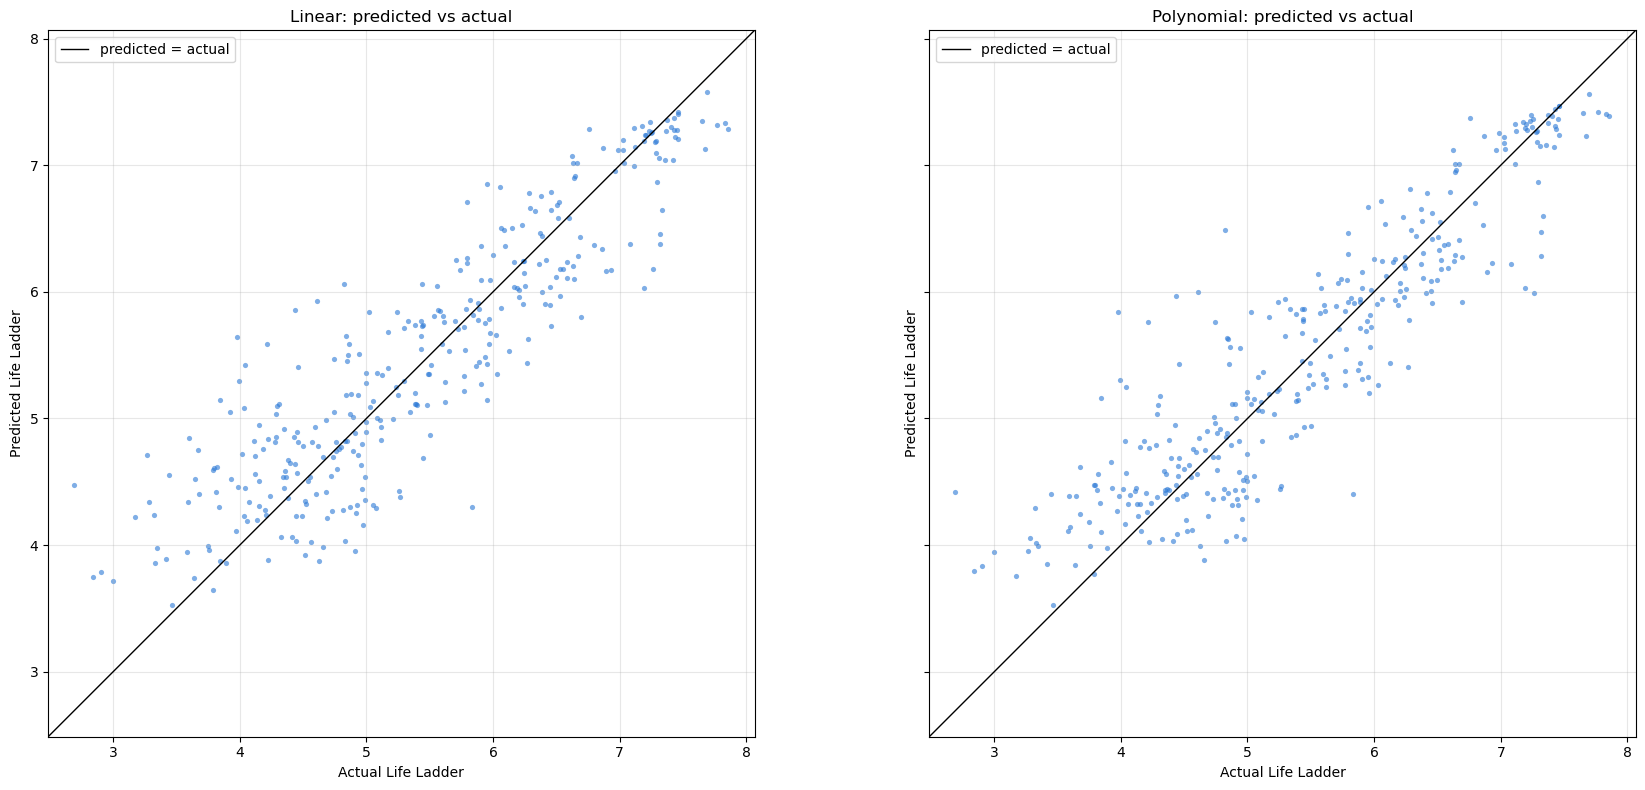

In [8]:
PLOTTING.predicted_vs_actual(actual=y_test, predictions=predictions);

## By Value

Rows, mean error and rmse in each band: first by actual value for both models, then by the value the final model predicted.

In [9]:
BAND_EDGES = [-np.inf, 4, 5, 6, 7, np.inf]
BAND_LABELS = ["below 4", "4 to 5", "5 to 6", "6 to 7", "7 and above"]


def band(values, name):
	"""The Life Ladder band of each value (ex "4 to 5" holds 4 and leaves out 5), as a Series called name."""
	return pd.cut(values, BAND_EDGES, labels=BAND_LABELS, right=False).rename(name)


display(SCORING.error_by_group(y_test, predictions, by=band(y_test, "actual value")).round(4))
display(SCORING.error_by_group(y_test, predictions[[FINAL]], by=band(predictions[FINAL], f"value predicted by {FINAL}")).round(4))

rows mean error               rmse           
                      Linear Polynomial  Linear Polynomial
actual value                                              
below 4        37     0.7325     0.6855  0.8693     0.7960
4 to 5        106     0.1439     0.1066  0.5281     0.5309
5 to 6         82    -0.0437    -0.0279  0.4405     0.4186
6 to 7         66    -0.1025    -0.0829  0.4098     0.3698
7 and above    43    -0.2357    -0.1887  0.4082     0.4177

,rows,mean error,rmse
,,Polynomial,Polynomial
value predicted by Polynomial,,,
below 4,14,0.3109,0.6079
4 to 5,115,0.0414,0.5020
5 to 6,97,0.1275,0.5881
6 to 7,65,-0.0235,0.4657
7 and above,43,0.0194,0.2370


## Results

- **The largest misses are on the rows with a low actual value.** The 37 rows below 4 have an rmse of 0.8693 for the linear model and 0.7960 for the polynomial one, against 0.3698 to 0.5309 in the other four bands. By actual value both models pull the ends toward the middle: the mean error falls band by band, from 0.7325 and 0.6855 below 4 to -0.2357 and -0.1887 at 7 and above.
- **Part of the miss at the low end is a level the final model gets wrong, not only an effect of the grouping.** By predicted value its mean error is within 0.1275 of 0 in the four bands from 4 up, and 0.3109 on the rows it predicts below 4: where it predicts a low value, the actual value is lower still. That band holds only 14 rows.
- **The final model is most accurate where it predicts a high value:** an rmse of 0.2370 on the 43 rows it predicts at 7 and above, against 0.4657 to 0.6079 in the other bands.
- **The polynomial model's gain is not in every band.** By actual value it is ahead of the linear model below 4 (0.7960 against 0.8693), from 5 to 6 (0.4186 against 0.4405) and from 6 to 7 (0.3698 against 0.4098), and slightly behind from 4 to 5 (0.5309 against 0.5281) and at 7 and above (0.4177 against 0.4082).